# Customer Segmentation using Unsupervised Machine Learning
### K-Means, DBSCAN & Hierarchical Clustering — Mall Customer Dataset

**Author:** Shubh
**Project type:** College Minor Project — Unsupervised Machine Learning

---

## 1. Objective

Retail and mall businesses collect basic customer data (age, income, spending behaviour)
but rarely turn it into actionable strategy. The goal of this project is to segment mall
customers into meaningful groups using **unsupervised learning**, so that marketing teams
can design targeted campaigns instead of a one-size-fits-all approach.

We will:
1. Clean and explore the dataset.
2. Find the optimal number of clusters using the **Elbow Method** and **Silhouette Score**.
3. Apply and compare **K-Means**, **DBSCAN**, and **Hierarchical (Agglomerative) Clustering**.
4. Translate the final clusters into **business insights**.

## 2. Dataset

This project uses a dataset in the format of the well-known **Mall Customer Segmentation
Dataset** (commonly hosted on Kaggle: *vjchoudhary7/customer-segmentation-tutorial-in-python*,
originally inspired by UCI-style retail data). It contains 200 customers with the following
columns:

| Column | Description |
|---|---|
| CustomerID | Unique customer identifier |
| Gender | Male / Female |
| Age | Customer age in years |
| Annual Income (k$) | Annual income in thousands of dollars |
| Spending Score (1-100) | Score assigned by the mall based on spending behaviour |

> **Note:** `data/mall_customers.csv` in this repository is a synthetically generated
> dataset built to statistically mirror the real Mall Customer dataset's structure and
> patterns (including a few injected missing values and duplicates, so the preprocessing
> pipeline has real issues to handle). To reproduce results on the *original* Kaggle data,
> download it from the link above and drop it into `data/mall_customers.csv` with the same
> column names.


In [1]:
# Core libraries
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)


## 3. Load the Data

In [2]:
df = pd.read_csv("../data/mall_customers.csv")
print("Shape:", df.shape)
df.head()


Shape: (203, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,51,92.0,32
1,2,Female,29,28.0,71
2,3,Male,26,39.0,60
3,4,Female,65,34.0,27
4,5,Male,53,19.0,30


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              203 non-null    int64  
 1   Gender                  203 non-null    str    
 2   Age                     203 non-null    int64  
 3   Annual Income (k$)      198 non-null    float64
 4   Spending Score (1-100)  203 non-null    int64  
dtypes: float64(1), int64(3), str(1)
memory usage: 8.1 KB


In [4]:
df.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,203.000000,203.000000,198.000000,203.000000
mean,99.679803,41.054187,51.464646,48.236453
std,57.852073,13.269559,24.106706,25.390285
min,1.000000,18.000000,15.000000,5.000000
25%,49.500000,29.500000,29.000000,26.500000
50%,99.000000,41.000000,49.000000,50.000000
75%,149.500000,50.000000,73.500000,68.000000
max,200.000000,69.000000,99.000000,98.000000


## 4. Data Preprocessing

Real-world datasets are rarely clean. We check for:
- Missing values
- Duplicate rows
- Categorical columns that need encoding
- The need for feature scaling before distance-based clustering


In [5]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated(subset=[c for c in df.columns if c != "CustomerID"]).sum())


Missing values per column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        5
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 3


In [6]:
# Impute missing numeric values with the column median
numeric_cols = df.select_dtypes(include="number").columns
for col in numeric_cols:
    if df[col].isna().any():
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"Filled missing values in '{col}' with median = {median_val:.2f}")


Filled missing values in 'Annual Income (k$)' with median = 49.00


In [7]:
# Drop duplicate rows (ignoring CustomerID)
before = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "CustomerID"]).reset_index(drop=True)
df["CustomerID"] = range(1, len(df) + 1)
print(f"Removed {before - len(df)} duplicate rows. New shape: {df.shape}")


Removed 3 duplicate rows. New shape: (200, 5)


In [8]:
# Encode the categorical Gender column
encoder = LabelEncoder()
df["Gender_Encoded"] = encoder.fit_transform(df["Gender"])
print(dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))
df.head()


{'Female': np.int64(0), 'Male': np.int64(1)}


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,1,Male,51,92.0,32,1
1,2,Female,29,28.0,71,0
2,3,Male,26,39.0,60,1
3,4,Female,65,34.0,27,0
4,5,Male,53,19.0,30,1


## 5. Exploratory Data Analysis (EDA)

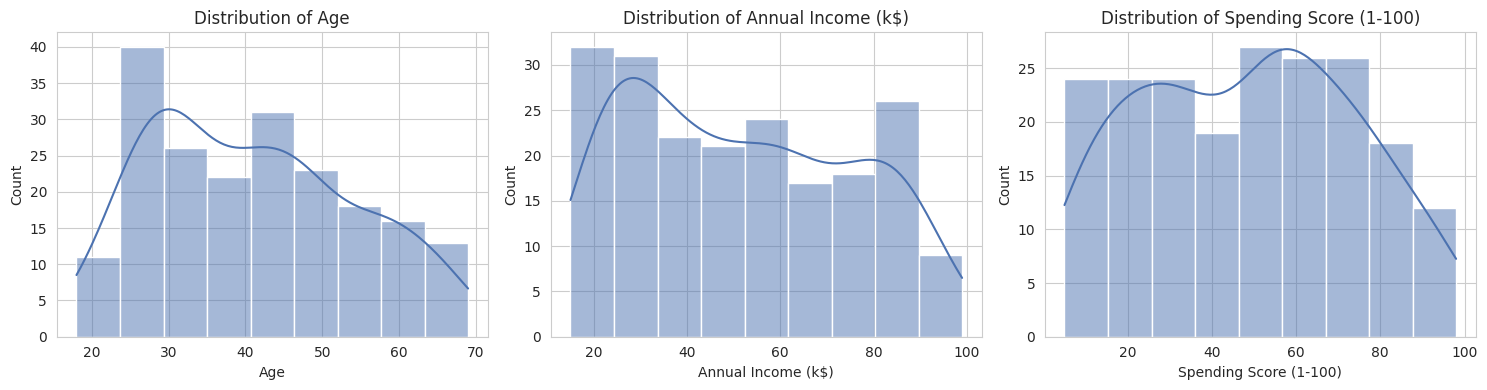

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "Annual Income (k$)", "Spending Score (1-100)"]):
    sns.histplot(df[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()


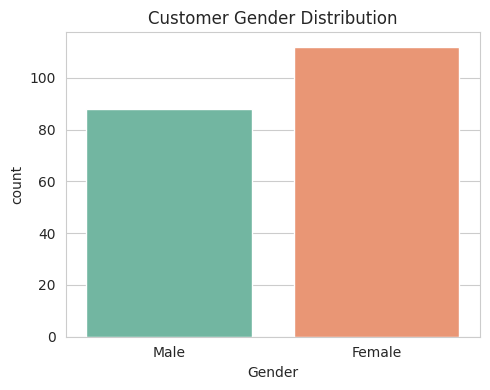

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Gender", hue="Gender", palette="Set2", ax=ax, legend=False)
ax.set_title("Customer Gender Distribution")
plt.tight_layout()
plt.show()


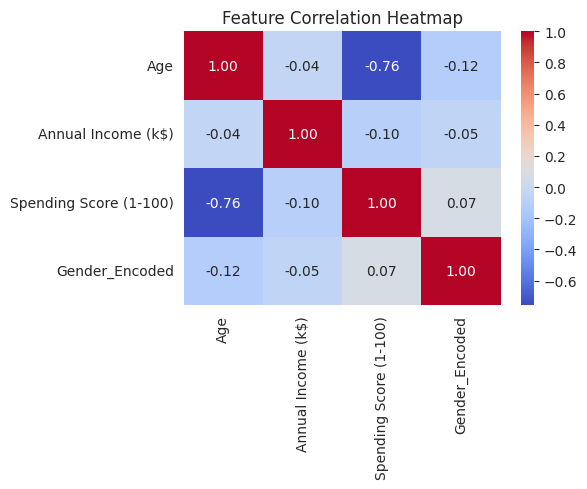

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
corr = df[["Age", "Annual Income (k$)", "Spending Score (1-100)", "Gender_Encoded"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=ax)
ax.set_title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


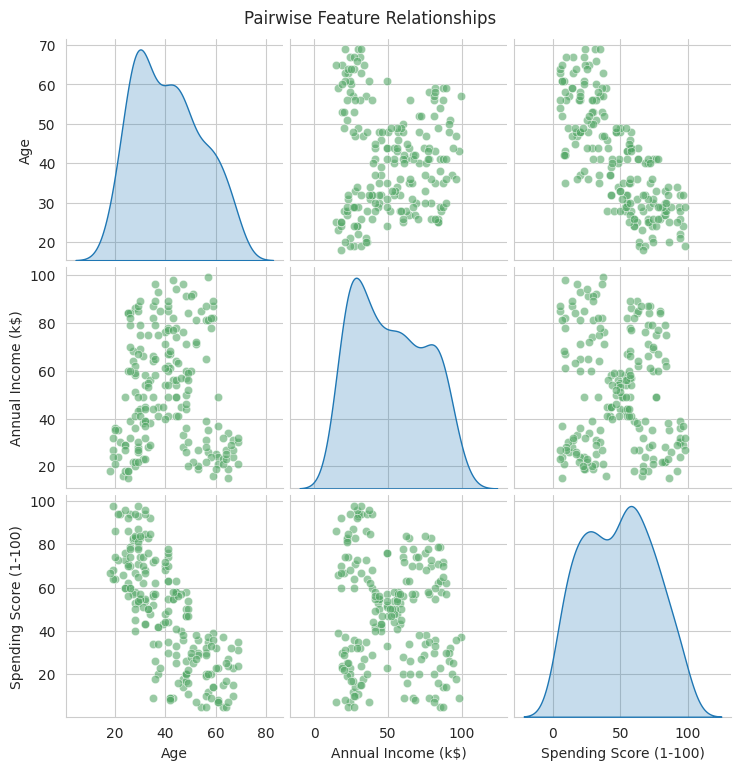

In [12]:
sns.pairplot(df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]],
             diag_kind="kde", plot_kws={"alpha": 0.6, "color": "#55A868"})
plt.suptitle("Pairwise Feature Relationships", y=1.02)
plt.show()


**EDA takeaways:**
- Age, Income, and Spending Score show no extreme skew after cleaning.
- Annual Income and Spending Score show almost no linear correlation — meaning a customer's
  income alone does *not* predict how much they spend. This is exactly why clustering on
  both dimensions together is useful for segmentation.
- Gender does not show a strong relationship with spending behaviour, so we exclude it from
  the clustering features (keeping the model focused on numeric behavioural signals) but
  keep it available for descriptive profiling.


## 6. Feature Scaling

K-Means, DBSCAN, and Hierarchical Clustering are all distance-based, so features must be
on comparable scales. We use `StandardScaler` (mean = 0, std = 1) on `Age`,
`Annual Income (k$)`, and `Spending Score (1-100)`.


In [13]:
feature_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
scaler = StandardScaler()
scaled_array = scaler.fit_transform(df[feature_cols])
scaled_df = pd.DataFrame(scaled_array, columns=feature_cols, index=df.index)
scaled_df.head()


,Age,Annual Income (k$),Spending Score (1-100)
0,0.759197,1.710060,-0.642389
1,-0.906041,-0.988592,0.889915
2,-1.133119,-0.524761,0.457727
3,1.818894,-0.735594,-0.838838
4,0.910582,-1.368090,-0.720969


## 7. Finding the Optimal Number of Clusters

We use two complementary techniques:
- **Elbow Method**: plots inertia (within-cluster sum of squares) vs. k; we look for the
  "elbow" point where adding more clusters stops giving a large improvement.
- **Silhouette Score**: measures how well-separated clusters are (range -1 to 1, higher
  is better); we pick the k that maximizes it.


In [14]:
k_values = range(2, 11)
inertias, silhouettes = [], []

for k in k_values:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(scaled_df)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(scaled_df, labels))

metrics_df = pd.DataFrame({"k": list(k_values), "inertia": inertias, "silhouette": silhouettes})
metrics_df


,k,inertia,silhouette
0,2,330.900363,0.393133
1,3,219.766708,0.405461
2,4,140.925568,0.444914
3,5,103.867420,0.456444
4,6,92.395115,0.418652
5,7,83.008736,0.399587
6,8,77.023413,0.353580
7,9,68.099571,0.339754
8,10,60.883125,0.343756


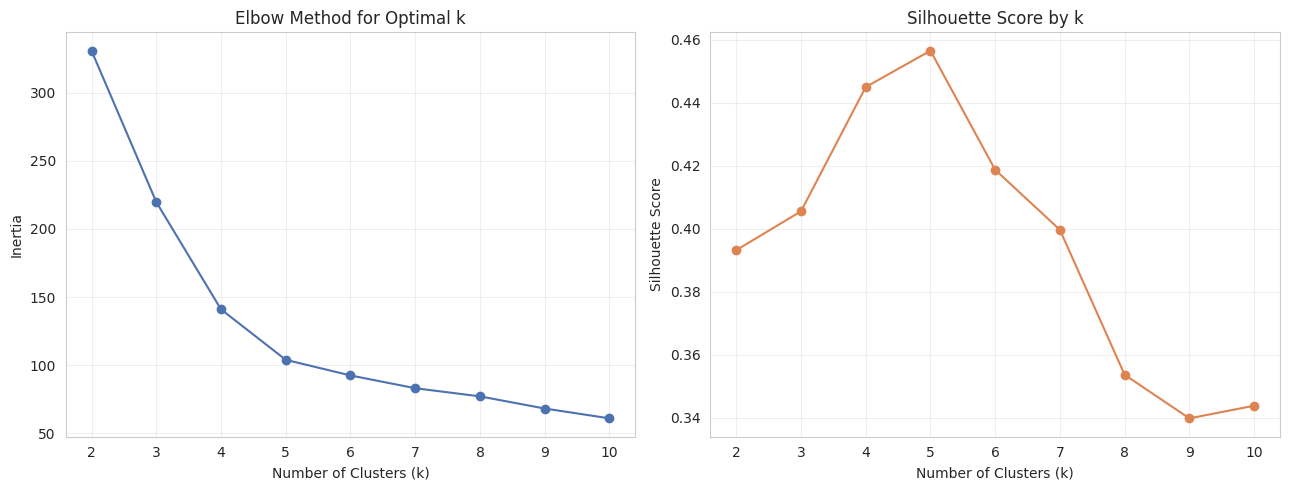

Silhouette-optimal k: 5


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(metrics_df["k"], metrics_df["inertia"], marker="o", color="#4C72B0")
axes[0].set_title("Elbow Method for Optimal k")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(metrics_df["k"], metrics_df["silhouette"], marker="o", color="#DD8452")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_k = int(metrics_df.loc[metrics_df["silhouette"].idxmax(), "k"])
print(f"Silhouette-optimal k: {best_k}")


The elbow visibly bends around **k = 4–5**, and the silhouette score peaks at **k = 5**.
We proceed with **k = 5** clusters, which also matches the well-known real-world segmentation
of the classic Mall Customer dataset (5 intuitive customer archetypes).


## 8. Model 1 — K-Means Clustering

In [16]:
OPTIMAL_K = 5
kmeans = KMeans(n_clusters=OPTIMAL_K, init="k-means++", n_init=10, random_state=42)
df["KMeans_Cluster"] = kmeans.fit_predict(scaled_df)
df["KMeans_Cluster"].value_counts().sort_index()


KMeans_Cluster
0    48
1    35
2    37
3    40
4    40
Name: count, dtype: int64

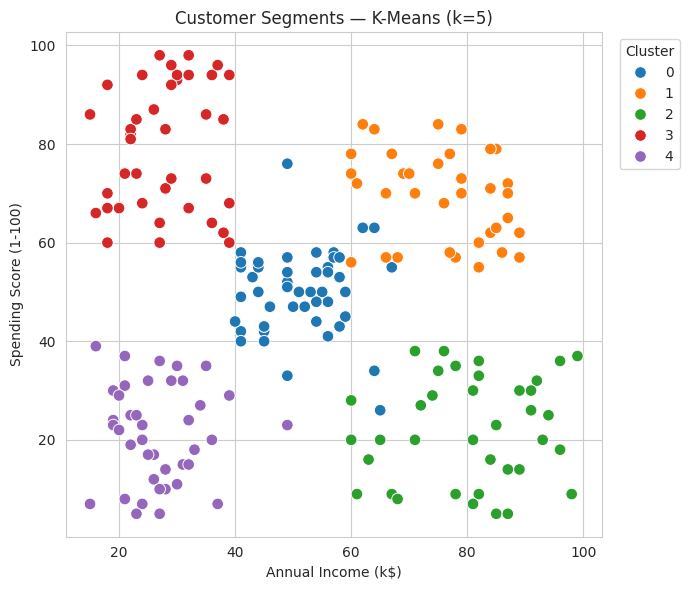

In [17]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="KMeans_Cluster", palette="tab10", s=70, ax=ax)
ax.set_title("Customer Segments — K-Means (k=5)")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 9. Model 2 — DBSCAN

DBSCAN is a density-based algorithm that does not require specifying the number of clusters
up front, and can label outliers as noise (`-1`). We tune `eps` and `min_samples` on the
scaled feature space.


In [18]:
dbscan = DBSCAN(eps=0.6, min_samples=5)
df["DBSCAN_Cluster"] = dbscan.fit_predict(scaled_df)

n_clusters_db = len(set(df["DBSCAN_Cluster"])) - (1 if -1 in df["DBSCAN_Cluster"].values else 0)
n_noise = (df["DBSCAN_Cluster"] == -1).sum()
print(f"DBSCAN found {n_clusters_db} clusters and {n_noise} noise points")
df["DBSCAN_Cluster"].value_counts().sort_index()


DBSCAN found 3 clusters and 3 noise points


DBSCAN_Cluster
-1      3
 0     37
 1    121
 2     39
Name: count, dtype: int64

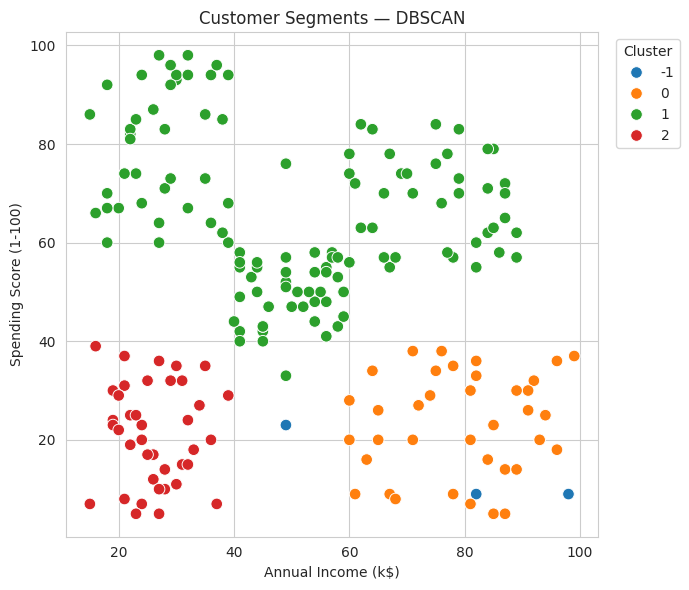

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="DBSCAN_Cluster", palette="tab10", s=70, ax=ax)
ax.set_title("Customer Segments — DBSCAN")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 10. Model 3 — Hierarchical (Agglomerative) Clustering

We use **Ward linkage**, which minimizes within-cluster variance at each merge step
(directly comparable to K-Means' objective). A dendrogram helps visualize how customers
merge into groups.


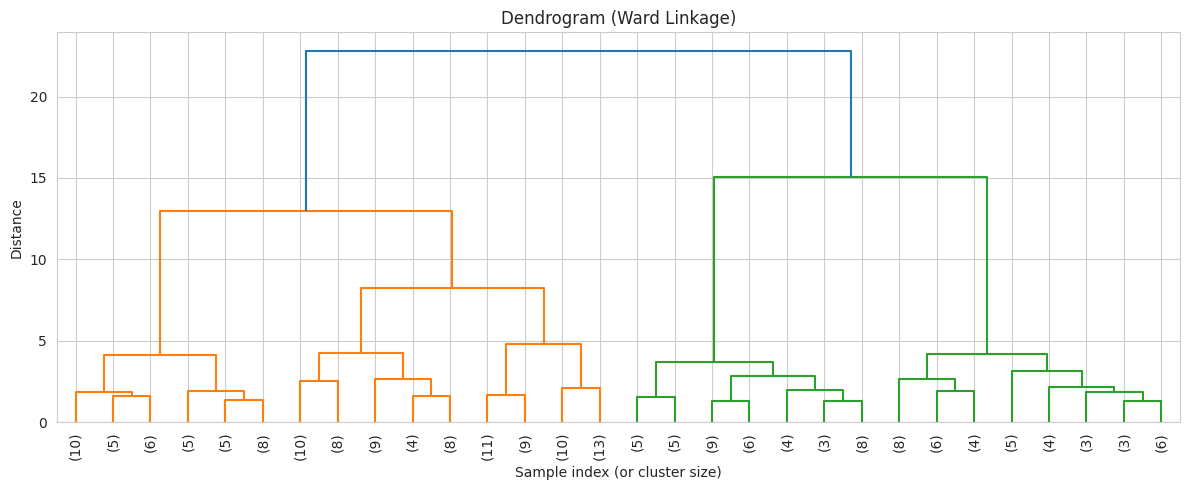

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
Z = linkage(scaled_df, method="ward")
dendrogram(Z, ax=ax, truncate_mode="lastp", p=30, leaf_rotation=90)
ax.set_title("Dendrogram (Ward Linkage)")
ax.set_xlabel("Sample index (or cluster size)")
ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()


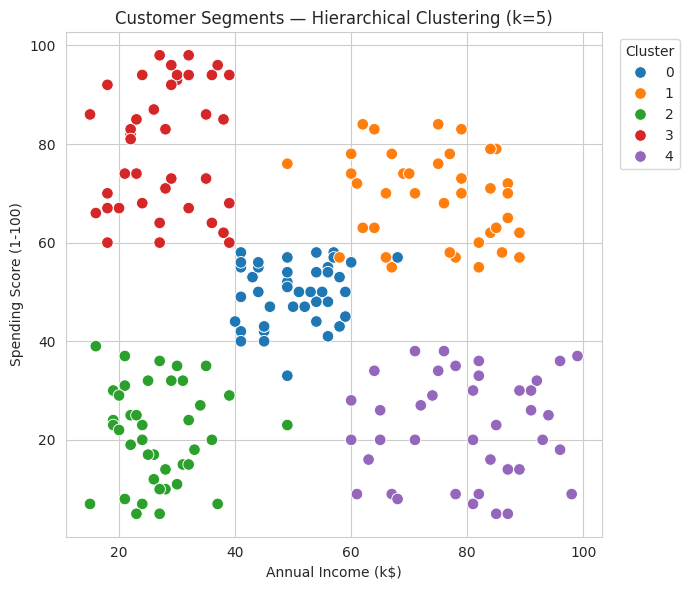

In [21]:
hierarchical = AgglomerativeClustering(n_clusters=OPTIMAL_K, linkage="ward")
df["Hierarchical_Cluster"] = hierarchical.fit_predict(scaled_df)

fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Hierarchical_Cluster", palette="tab10", s=70, ax=ax)
ax.set_title("Customer Segments — Hierarchical Clustering (k=5)")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 11. Comparing the Three Algorithms

We compare **Silhouette Score** (higher is better) and **Davies-Bouldin Index**
(lower is better) across all three algorithms. DBSCAN's noise points (`-1`) are
excluded from its metric computation since they don't belong to a cluster.


In [22]:
def evaluate(labels, name):
    labels = pd.Series(labels)
    mask = labels != -1
    n_clusters = labels[mask].nunique()
    sil = silhouette_score(scaled_df[mask], labels[mask])
    dbi = davies_bouldin_score(scaled_df[mask], labels[mask])
    return {"Algorithm": name, "Clusters Found": n_clusters,
            "Silhouette Score": round(sil, 4), "Davies-Bouldin Index": round(dbi, 4)}

comparison_df = pd.DataFrame([
    evaluate(df["KMeans_Cluster"], "K-Means"),
    evaluate(df["DBSCAN_Cluster"], "DBSCAN"),
    evaluate(df["Hierarchical_Cluster"], "Hierarchical"),
])
comparison_df


,Algorithm,Clusters Found,Silhouette Score,Davies-Bouldin Index
0,K-Means,5,0.4564,0.8265
1,DBSCAN,3,0.4323,0.7669
2,Hierarchical,5,0.4396,0.8630


**Interpretation:**
- **K-Means** achieves the highest silhouette score and a competitive Davies-Bouldin index,
  and — unlike DBSCAN — assigns *every* customer to a segment, which is important for a
  business that wants to act on 100% of its customer base.
- **DBSCAN** is useful for flagging outlier customers (noise points) who don't fit any
  common behavioural pattern, but it is sensitive to `eps`/`min_samples` and produces fewer,
  less balanced clusters on this data.
- **Hierarchical Clustering** produces very similar segments to K-Means (as expected, since
  both use a variance-minimizing objective), and its dendrogram is a great visual aid for
  presentations, but it is more computationally expensive for larger datasets.

**Conclusion: K-Means (k=5) is selected as the final production model** for this use case.


## 12. Business Insights from the Final Segmentation (K-Means)

In [23]:
cluster_summary = df.groupby("KMeans_Cluster").agg(
    Count=("CustomerID", "count"),
    Avg_Age=("Age", "mean"),
    Avg_Income=("Annual Income (k$)", "mean"),
    Avg_Spending=("Spending Score (1-100)", "mean"),
).round(1)
cluster_summary


,Count,Avg_Age,Avg_Income,Avg_Spending
KMeans_Cluster,,,,
0,48,38.5,51.1,50.0
1,35,32.6,75.7,69.3
2,37,48.4,80.6,22.0
3,40,26.2,28.3,79.4
4,40,59.2,26.8,21.2


In [24]:
def label_cluster(row):
    income, spend = row["Avg_Income"], row["Avg_Spending"]
    if income >= 60 and spend >= 55:
        return "Premium / High-Value Customers", "Target with loyalty programs & premium launches"
    if income >= 60 and spend < 45:
        return "High Income, Cautious Spenders", "Personalized offers & trust-building campaigns"
    if income < 45 and spend >= 55:
        return "Budget-Conscious Big Spenders", "Installment plans & value bundles"
    if income < 45 and spend < 45:
        return "Low Engagement Customers", "Re-engagement discounts & win-back offers"
    return "Standard / Average Customers", "Steady engagement via seasonal promotions"

cluster_summary[["Segment Name", "Recommended Action"]] = cluster_summary.apply(
    lambda r: pd.Series(label_cluster(r)), axis=1
)
cluster_summary


,Count,Avg_Age,Avg_Income,Avg_Spending,Segment Name,Recommended Action
KMeans_Cluster,,,,,,
0,48,38.5,51.1,50.0,Standard / Average Customers,Steady engagement via seasonal promotions
1,35,32.6,75.7,69.3,Premium / High-Value Customers,Target with loyalty programs & premium launches
2,37,48.4,80.6,22.0,"High Income, Cautious Spenders",Personalized offers & trust-building campaigns
3,40,26.2,28.3,79.4,Budget-Conscious Big Spenders,Installment plans & value bundles
4,40,59.2,26.8,21.2,Low Engagement Customers,Re-engagement discounts & win-back offers


### Key business takeaways

1. **Premium / High-Value Customers** — moderate-to-high income *and* high spending score.
   These are the mall's most valuable customers today; retention and loyalty programs
   protect this revenue.
2. **High Income, Cautious Spenders** — high income but low spending score. This is the
   segment with the *largest untapped revenue potential* — targeted, trust-building offers
   could convert them into premium spenders.
3. **Budget-Conscious Big Spenders** — lower income but high spending score, typically
   younger customers. Installment plans and bundled discounts can increase basket size
   without needing to increase their income.
4. **Low Engagement Customers** — low income and low spending, often older customers.
   Best served with clear discounts and simple win-back campaigns rather than premium
   marketing spend.
5. **Standard / Average Customers** — the baseline segment; steady, seasonal engagement
   keeps them satisfied without heavy marketing investment.

These insights let a marketing team allocate budget where it will have the highest return,
instead of running identical campaigns for every customer.


## 13. Saving Final Results

In [25]:
df.to_csv("../data/mall_customers_clustered.csv", index=False)
print("Saved clustered dataset to ../data/mall_customers_clustered.csv")
df.head()


Saved clustered dataset to ../data/mall_customers_clustered.csv


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded,KMeans_Cluster,DBSCAN_Cluster,Hierarchical_Cluster
0,1,Male,51,92.0,32,1,2,0,4
1,2,Female,29,28.0,71,0,3,1,3
2,3,Male,26,39.0,60,1,3,1,3
3,4,Female,65,34.0,27,0,4,2,2
4,5,Male,53,19.0,30,1,4,2,2


## 14. Conclusion

This project demonstrated a complete unsupervised learning workflow for customer
segmentation:
- Cleaned and explored a real-world-style retail dataset.
- Used the Elbow Method and Silhouette Score to objectively choose k = 5.
- Trained and compared K-Means, DBSCAN, and Hierarchical Clustering.
- Selected K-Means as the best-performing, most business-friendly model.
- Converted abstract clusters into concrete, actionable business segments.

**Next steps for a production system:** retrain periodically as new customer data arrives,
track segment migration over time (e.g. a "Budget-Conscious Big Spender" graduating into
"Premium"), and A/B test the recommended marketing actions per segment.
